# TransitIQ: traffic data analysis and model comparison

This notebook cleans the reference traffic dataset, explores its patterns, compares five regression models, and plots holdout results. **The labeled traffic counts are from Minnesota, not Mumbai**, so the metrics below do not measure Mumbai accuracy. Run Jupyter from the repository root.

### 1.1 Imports and reproducibility

This section imports the analysis tools and fixes the random seed so model comparisons are repeatable.

In [1]:
# Section: 1.1 Imports and reproducibility
# Purpose: This section imports the analysis tools and fixes the random seed so model comparisons are repeatable.

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=RuntimeWarning)
RANDOM_STATE = 42
DATA_PATH = Path("data/Metro_Interstate_Traffic_Volume.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found; start Jupyter from the repository root.")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

### 2.1 Load and inspect the dataset

Inspect columns, data types, missing values, and basic ranges before changing the raw records.

In [2]:
# Section: 2.1 Load and inspect the dataset
# Purpose: Inspect columns, data types, missing values, and basic ranges before changing the raw records.

raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype"))
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing"))
display(raw.describe(include="all").T)

Shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


,dtype
holiday,object
temp,float64
rain_1h,float64
snow_1h,float64
clouds_all,int64
weather_main,object
weather_description,object
date_time,object
traffic_volume,int64


,missing
holiday,48143
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
holiday,61,11,Labor Day,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp,48204.0,NaN,NaN,NaN,281.20587,13.338232,0.0,272.16,282.45,291.806,310.07
rain_1h,48204.0,NaN,NaN,NaN,0.334264,44.789133,0.0,0.0,0.0,0.0,9831.3
snow_1h,48204.0,NaN,NaN,NaN,0.000222,0.008168,0.0,0.0,0.0,0.0,0.51
clouds_all,48204.0,NaN,NaN,NaN,49.362231,39.01575,0.0,1.0,64.0,90.0,100.0
weather_main,48204,11,Clouds,15164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_description,48204,38,sky is clear,11665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_time,48204,40575,2013-05-19 10:00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic_volume,48204.0,NaN,NaN,NaN,3259.818355,1986.86067,0.0,1193.0,3380.0,4933.0,7280.0


### 3.1 Validate columns and clean timestamps

Keep rows with valid timestamps and nonnegative traffic labels, then order them chronologically.

In [3]:
# Section: 3.1 Validate columns and clean timestamps
# Purpose: Keep rows with valid timestamps and nonnegative traffic labels, then order them chronologically.

# Start from the source CSV; retain only rows with a valid timestamp and observed target.
df = raw.copy()
required = ["date_time", "traffic_volume", "temp", "rain_1h", "clouds_all"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
for column in ["traffic_volume", "temp", "rain_1h", "clouds_all"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df = df.dropna(subset=["date_time", "traffic_volume"]).copy()
df = df[np.isfinite(df["traffic_volume"]) & (df["traffic_volume"] >= 0)].copy()
df = df.sort_values("date_time").reset_index(drop=True)
print("Rows after timestamp and target cleaning:", len(df))

Rows after timestamp and target cleaning: 48204


 48204


### 3.2 Convert temperature and fill weather gaps

Convert Kelvin temperatures to Celsius and use documented defaults where the reference dataset lacks weather fields.

In [4]:
# Section: 3.2 Convert temperature and fill weather gaps
# Purpose: Convert Kelvin temperatures to Celsius and use documented defaults where the reference dataset lacks weather fields.

# The Metro Interstate source records temperature in Kelvin.
df.loc[df["temp"] <= 0, "temp"] = np.nan
if df["temp"].median() > 100:
    df["temp"] = df["temp"] - 273.15
df["temp"] = df["temp"].clip(-50, 60).fillna(df["temp"].median())
df["rain_1h"] = df["rain_1h"].fillna(0).clip(0, 500)
df["clouds_all"] = df["clouds_all"].fillna(50).clip(0, 100)
# Humidity and wind are not supplied in this dataset.
df["humidity"] = 60.0
df["wind"] = 10.0
print("Temperature range (C):", round(df["temp"].min(), 1), "to", round(df["temp"].max(), 1))

Temperature range (C): -29.8 to 36.9


### 3.3 Create calendar features

Extract hour, weekday, month, and holiday indicators to represent recurring traffic patterns.

In [5]:
# Section: 3.3 Create calendar features
# Purpose: Extract hour, weekday, month, and holiday indicators to represent recurring traffic patterns.

df["hour"] = df["date_time"].dt.hour
df["day"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month
if "holiday" in df.columns:
    holiday = df["holiday"].fillna("None").astype(str).str.lower()
    df["is_holiday"] = (~holiday.isin(["none", "nan"])).astype(int)
else:
    df["is_holiday"] = 0
display(df[["date_time", "hour", "day", "month", "is_holiday"]].head())

,date_time,hour,day,month,is_holiday
0,2012-10-02 09:00:00,9,1,10,0
1,2012-10-02 10:00:00,10,1,10,0
2,2012-10-02 11:00:00,11,1,10,0
3,2012-10-02 12:00:00,12,1,10,0
4,2012-10-02 13:00:00,13,1,10,0


### 3.4 Engineer weather features

Build the interaction and weather indicators used by the training script so notebook results match the API model inputs.

In [6]:
# Section: 3.4 Engineer weather features
# Purpose: Build the interaction and weather indicators used by the training script so notebook results match the API model inputs.

# Pair temperature with humidity; humidity itself is a fixed placeholder in this dataset.
df["temp_humidity"] = df["temp"] * df["humidity"]
df["rain_intensity"] = df["rain_1h"] * df["clouds_all"]
df["weather_severity"] = (
    .3 * df["temp"] + .2 * df["humidity"] + .2 * df["clouds_all"]
    + .1 * df["wind"] + .2 * df["rain_1h"]
)
# Approximate weather indices follow the formulas in train_model.py.
df["dew_point"] = df["temp"] - (100 - df["humidity"]) / 5
df["heat_index"] = .5 * (
    df["temp"] + 61 + (df["temp"] - 68) * 1.2 + df["humidity"] * .094
)
df["wind_chill"] = (
    13.12 + .6215 * df["temp"] - 11.37 * (df["wind"] ** .16)
    + .3965 * df["temp"] * (df["wind"] ** .16)
)
safe_temp = df["temp"].clip(-50, 60)
df["abs_humidity"] = (
    6.112 * np.exp((17.67 * safe_temp) / (safe_temp + 243.5))
    * df["humidity"] / 100
) / 100
df["rain_humidity_ratio"] = df["rain_1h"] / (df["humidity"] + 1)
df["cloud_wind_interaction"] = df["clouds_all"] * df["wind"]
df["humidity_comfort"] = (df["humidity"] - 45).abs()
# Binary indicators mark broad weather conditions for the tree models.
df["is_hot"] = (df["temp"] > 30).astype(int)
df["is_cold"] = (df["temp"] < 15).astype(int)
df["is_rain"] = (df["rain_1h"] > 0).astype(int)
df["weather_stability"] = df["wind"].abs() + (df["clouds_all"] - 50).abs() / 100
df["high_clouds"] = (df["clouds_all"] > 70).astype(int)
df["low_clouds"] = (df["clouds_all"] < 30).astype(int)
df["discomfort_index"] = (
    .4 * ((df["temp"] + df["heat_index"]) / 2) + .6 * df["humidity"] - 20
).clip(0, 100)
df["heat_index"] = df["heat_index"].clip(20, 60)
df["wind_chill"] = df["wind_chill"].clip(-50, 50)

### 3.5 Review the cleaned data

Check the final record count and date range before beginning analysis and model fitting.

In [7]:
# Section: 3.5 Review the cleaned data
# Purpose: Check the final record count and date range before beginning analysis and model fitting.

print(f"Clean records: {len(df):,}; removed: {len(raw) - len(df):,}")
print("Date range:", df["date_time"].min(), "to", df["date_time"].max())
display(df[["traffic_volume", "temp", "rain_1h", "clouds_all", "humidity", "wind"]].describe().T)

Clean records: 48,204; removed: 0
Date range: 2012-10-02 09:00:00 to 2018-09-30 23:00:00


,count,mean,std,min,25%,50%,75%,max
traffic_volume,48204.0,3259.818355,1986.860670,0.00,1193.00,3380.00,4933.000,7280.00
temp,48204.0,8.114467,12.708280,-29.76,-0.96,9.31,18.656,36.92
rain_1h,48204.0,0.140685,2.488038,0.00,0.00,0.00,0.000,500.00
clouds_all,48204.0,49.362231,39.015750,0.00,1.00,64.00,90.000,100.00
humidity,48204.0,60.000000,0.000000,60.00,60.00,60.00,60.000,60.00
wind,48204.0,10.000000,0.000000,10.00,10.00,10.00,10.000,10.00


### 4.1 Hourly and weekly traffic trends

The line plots show average daily traffic shape and how weekly average volume changes through the reference period.

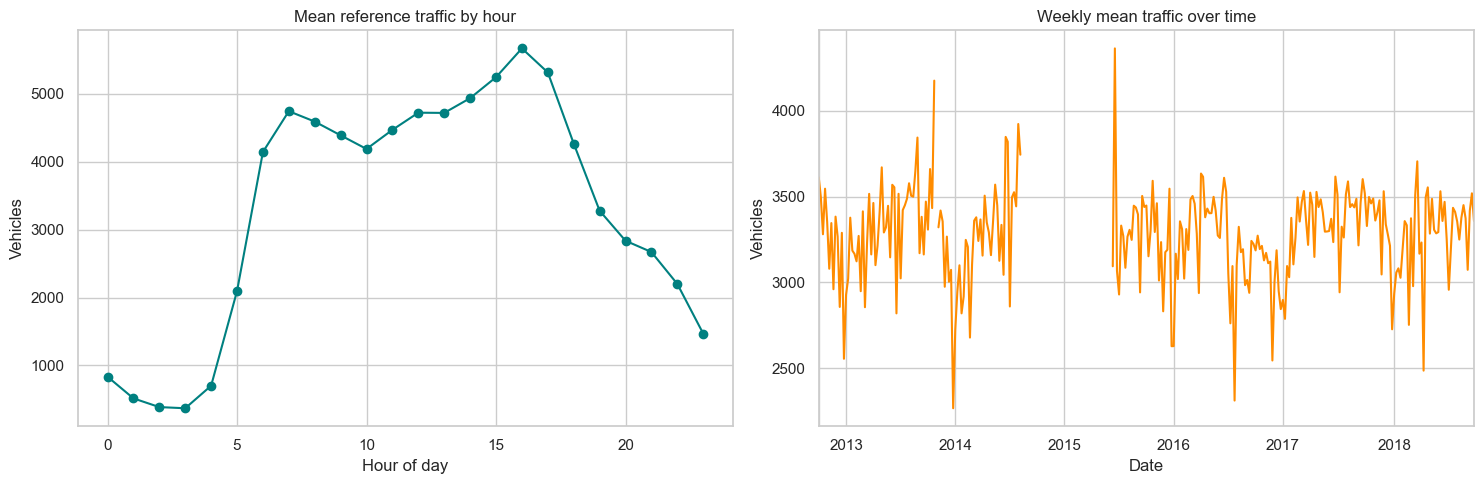

In [8]:
# Section: 4.1 Hourly and weekly traffic trends
# Purpose: The line plots show average daily traffic shape and how weekly average volume changes through the reference period.

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df.groupby("hour")["traffic_volume"].mean().plot(ax=axes[0], marker="o", color="teal")
axes[0].set(title="Mean reference traffic by hour", xlabel="Hour of day", ylabel="Vehicles")
df.set_index("date_time")["traffic_volume"].resample("W").mean().plot(ax=axes[1], color="darkorange")
axes[1].set(title="Weekly mean traffic over time", xlabel="Date", ylabel="Vehicles")
plt.tight_layout()
plt.show()

### 4.2 Monthly patterns and target distribution

These plots reveal seasonal differences and whether traffic volume is concentrated in particular ranges.

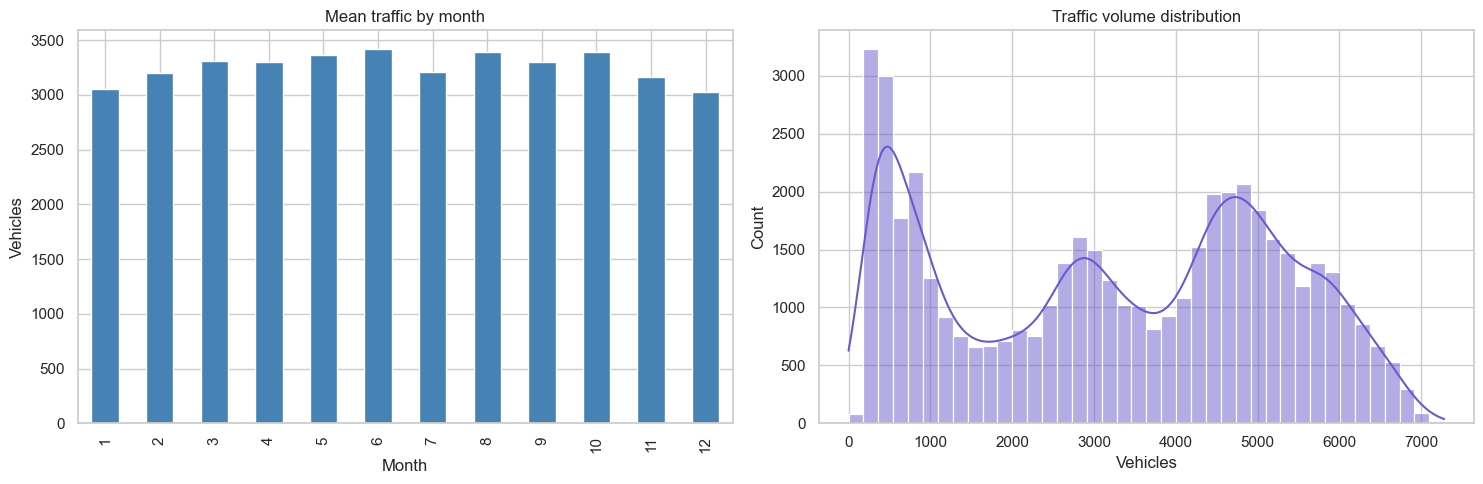

In [9]:
# Section: 4.2 Monthly patterns and target distribution
# Purpose: These plots reveal seasonal differences and whether traffic volume is concentrated in particular ranges.

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df.groupby("month")["traffic_volume"].mean().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="Mean traffic by month", xlabel="Month", ylabel="Vehicles")
sns.histplot(df["traffic_volume"], bins=40, kde=True, ax=axes[1], color="slateblue")
axes[1].set(title="Traffic volume distribution", xlabel="Vehicles")
plt.tight_layout()
plt.show()

### 5.1 Select features and split by time

Training on earlier records and testing on later records avoids mixing future observations into model fitting.

In [10]:
# Section: 5.1 Select features and split by time
# Purpose: Training on earlier records and testing on later records avoids mixing future observations into model fitting.

# Keep these feature names and ordering aligned with the API feature builder.
features = [
    "hour", "day", "month", "temp", "rain_1h", "clouds_all",
    "humidity", "wind", "is_holiday", "temp_humidity", "rain_intensity",
    "weather_severity", "dew_point", "heat_index", "wind_chill",
    "abs_humidity", "rain_humidity_ratio", "cloud_wind_interaction",
    "humidity_comfort", "is_hot", "is_cold", "is_rain", "weather_stability",
    "high_clouds", "low_clouds", "discomfort_index"
]
X = df[features].replace([np.inf, -np.inf], np.nan).fillna(0)
X = X.clip(-1_000_000, 1_000_000)
y = df["traffic_volume"].astype(float)
# Use the first 80% of time-ordered records for training and the latest 20% for evaluation.
split = int(len(df) * .8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
test_dates = df["date_time"].iloc[split:]
print("Train:", len(X_train), "| Test:", len(X_test), "| Test starts:", test_dates.min())

Train: 38563 | Test: 9641 | Test starts: 2017-11-01 20:00:00


### 6.1 Define the five candidate regressors

The candidates cover a linear baseline, individual tree, two ensemble methods, and XGBoost.

In [11]:
# Section: 6.1 Define the five candidate regressors
# Purpose: The candidates cover a linear baseline, individual tree, two ensemble methods, and XGBoost.

# All models use identical train/test rows; only Linear Regression needs feature scaling.
models = {
    # Scaled linear baseline: checks whether a simple linear relation is sufficient.
    "Linear Regression": Pipeline([
        ("scale", StandardScaler()), ("model", LinearRegression())
    ]),
    # One bounded-depth tree: interpretable nonlinear baseline.
    "Decision Tree": DecisionTreeRegressor(
        max_depth=15, min_samples_leaf=2, random_state=RANDOM_STATE
    ),
    # 100 trees averaged together to reduce a single-tree variance.
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=15, min_samples_leaf=2,
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    # Sequential boosting baseline using shallow trees.
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=.1, max_depth=3,
        random_state=RANDOM_STATE
    ),
    # Gradient-boosted trees; these parameters match train_model.py.
    "XGBoost": XGBRegressor(
        n_estimators=150, learning_rate=.05, max_depth=5,
        subsample=.8, colsample_bytree=.8,
        objective="reg:squarederror", eval_metric="rmse",
        tree_method="hist", n_jobs=-1,
        random_state=RANDOM_STATE, verbosity=0
    ),
}

### 6.2 Fit models and calculate holdout errors

MAE, RMSE, and R-squared provide complementary measures of error size and explained variance.

In [12]:
# Section: 6.2 Fit models and calculate holdout errors
# Purpose: MAE, RMSE, and R-squared provide complementary measures of error size and explained variance.

results, predictions, fitted = [], {}, {}
# Fit each candidate and score its predictions on the later holdout period.
for name, estimator in models.items():
    started = time.perf_counter()
    estimator.fit(X_train, y_train)
    elapsed = time.perf_counter() - started
    pred = estimator.predict(X_test)
    fitted[name] = estimator
    predictions[name] = pred
    results.append({
        "Model": name,
        # MAE is the average absolute count error; RMSE penalizes large misses more.
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "Training time (s)": elapsed,
    })
comparison = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
display(comparison.round(4))
# The project selects the largest holdout R-squared; do not call this a Mumbai score.
best_name = comparison.loc[0, "Model"]
print("Highest holdout R2:", best_name)

,Model,MAE,RMSE,R2,Training time (s)
0,XGBoost,301.5177,522.2000,0.9296,0.5545
1,Random Forest,293.9520,531.6440,0.9270,7.2086
2,Gradient Boosting,377.0304,590.4914,0.9099,12.6128
3,Decision Tree,331.7994,604.3311,0.9057,0.5604
4,Linear Regression,1566.8675,1793.7657,0.1689,0.0776


Highest holdout R2: XGBoost


### 7.1 Compare model metrics visually

The bar charts make it easy to compare model errors and the R-squared ranking at a glance.

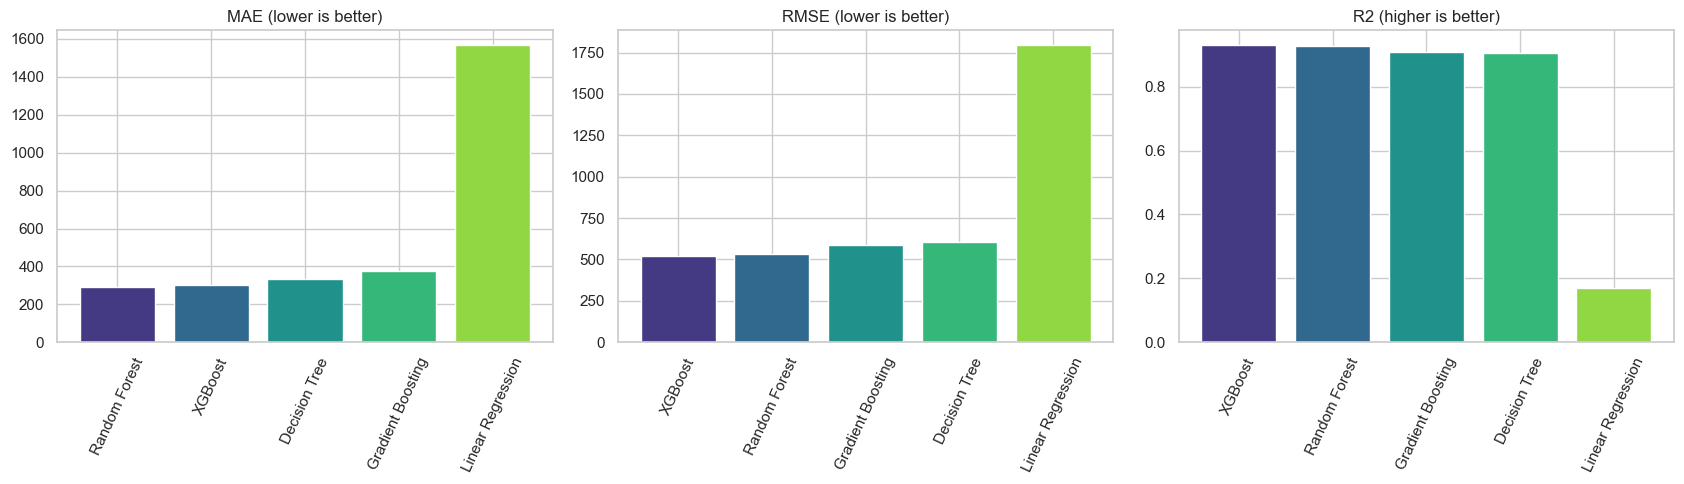

In [13]:
# Section: 7.1 Compare model metrics visually
# Purpose: The bar charts make it easy to compare model errors and the R-squared ranking at a glance.

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric, title in zip(
    axes, ["MAE", "RMSE", "R2"],
    ["MAE (lower is better)", "RMSE (lower is better)", "R2 (higher is better)"]
):
    ordered = comparison.sort_values(metric, ascending=(metric != "R2"))
    ax.bar(ordered["Model"], ordered[metric], color=sns.color_palette("viridis", len(ordered)))
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()

### 8.1 Plot observed and estimated traffic over time

This line graph compares the selected model with observed Minnesota counts in the last 200 test rows.

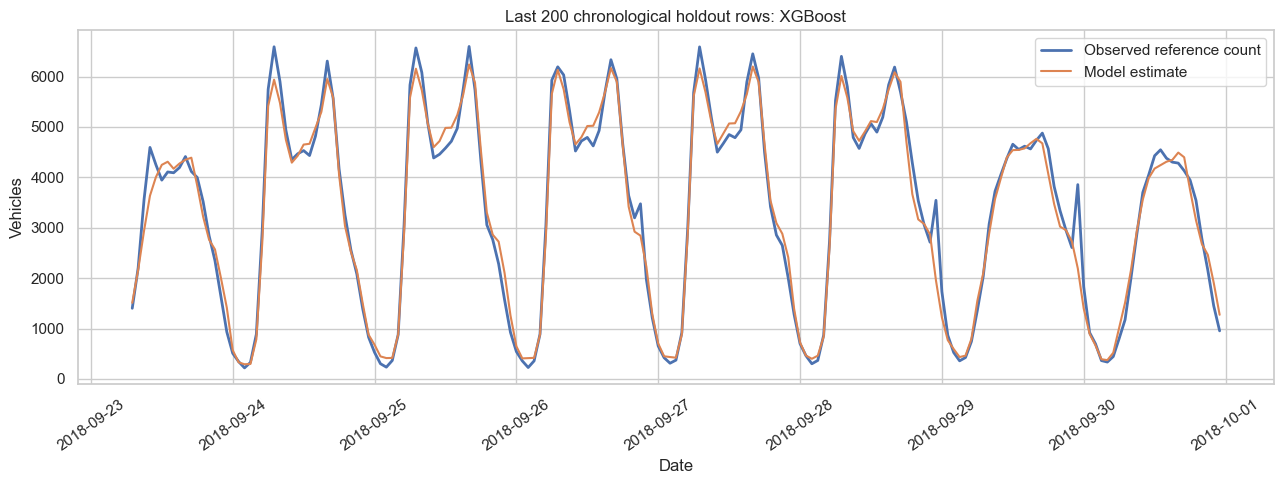

In [14]:
# Section: 8.1 Plot observed and estimated traffic over time
# Purpose: This line graph compares the selected model with observed Minnesota counts in the last 200 test rows.

best_pred = predictions[best_name]
n = min(200, len(y_test))
plt.figure(figsize=(13, 5))
plt.plot(test_dates.iloc[-n:], y_test.iloc[-n:], label="Observed reference count", linewidth=2)
plt.plot(test_dates.iloc[-n:], best_pred[-n:], label="Model estimate", linewidth=1.5)
plt.title(f"Last {n} chronological holdout rows: {best_name}")
plt.xlabel("Date")
plt.ylabel("Vehicles")
plt.xticks(rotation=35)
plt.legend()
plt.tight_layout()
plt.show()

### 8.2 Inspect predicted-versus-observed values

Points near the dashed diagonal indicate estimates close to the observed reference counts.

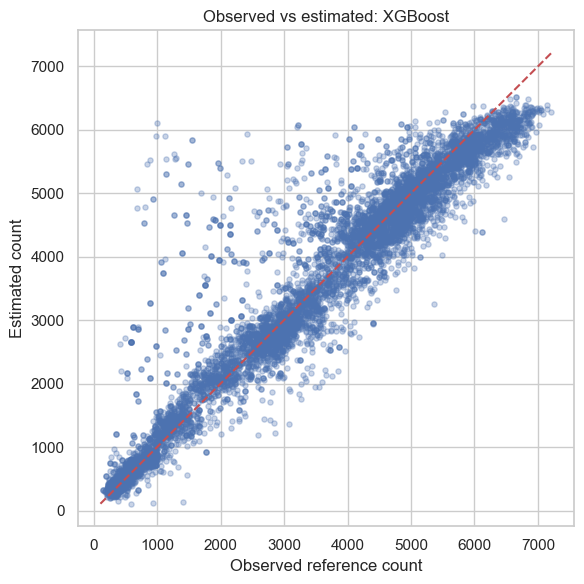

In [15]:
# Section: 8.2 Inspect predicted-versus-observed values
# Purpose: Points near the dashed diagonal indicate estimates close to the observed reference counts.

lo = min(y_test.min(), best_pred.min())
hi = max(y_test.max(), best_pred.max())
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=.3, s=14)
plt.plot([lo, hi], [lo, hi], "r--")
plt.title(f"Observed vs estimated: {best_name}")
plt.xlabel("Observed reference count")
plt.ylabel("Estimated count")
plt.tight_layout()
plt.show()

### 8.3 Review residuals

Residuals show whether the selected model tends to overestimate or underestimate particular volume ranges.

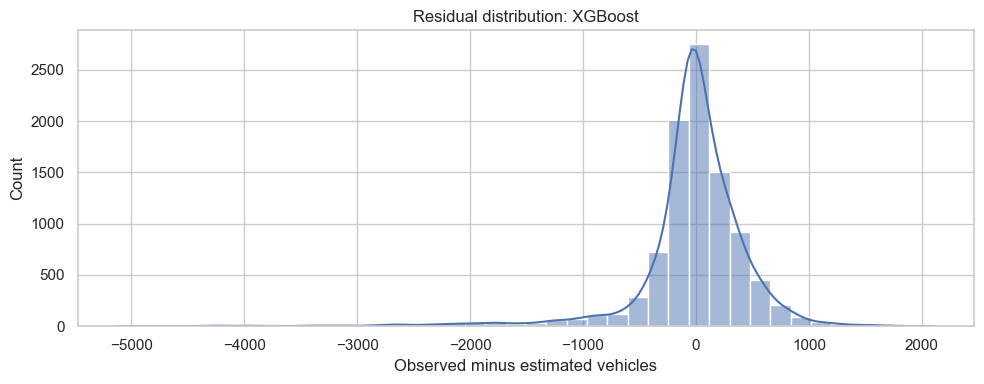

In [16]:
# Section: 8.3 Review residuals
# Purpose: Residuals show whether the selected model tends to overestimate or underestimate particular volume ranges.

residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(10, 4))
sns.histplot(residuals, bins=40, kde=True)
plt.title(f"Residual distribution: {best_name}")
plt.xlabel("Observed minus estimated vehicles")
plt.tight_layout()
plt.show()

### 9.1 Inspect Random Forest feature importance

This plot explains which inputs the Random Forest relied on; it is descriptive, not causal evidence.

,Random Forest importance
hour,0.847151
day,0.110808
weather_severity,0.009396
month,0.007645
dew_point,0.003254
temp,0.003243
abs_humidity,0.003237
wind_chill,0.003155
discomfort_index,0.003153
temp_humidity,0.003040


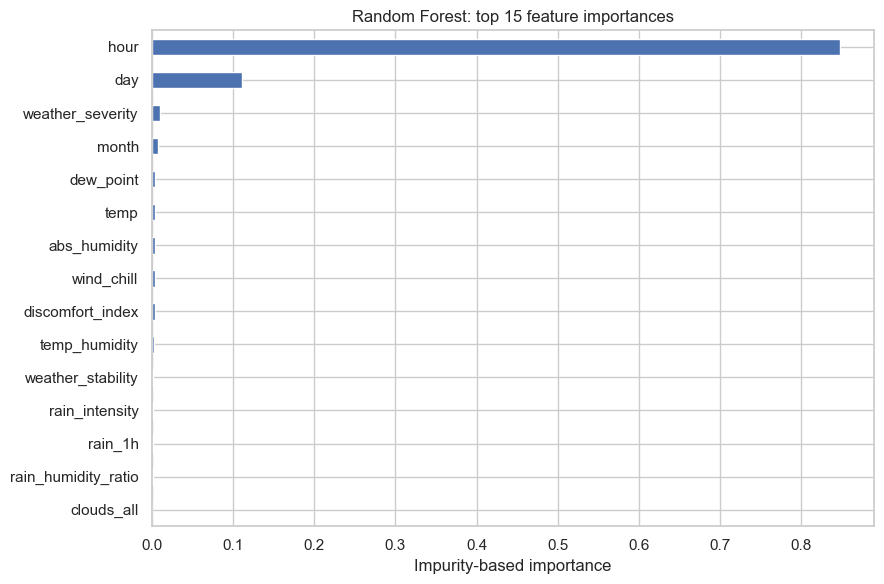

In [17]:
# Section: 9.1 Inspect Random Forest feature importance
# Purpose: This plot explains which inputs the Random Forest relied on; it is descriptive, not causal evidence.

# Show Random Forest importance specifically; this is descriptive, not causal.
rf = fitted["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
display(importance.head(15).to_frame("Random Forest importance"))
importance.head(15).sort_values().plot(
    kind="barh", figsize=(9, 6), title="Random Forest: top 15 feature importances"
)
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()

## 10. Interpretation and research limitations

Random Forest is a practical baseline for nonlinear tabular data; XGBoost can offer stronger boosting performance. The code selects by R-squared, so report the actual comparison table rather than claiming one model is universally best.

The source labels are Minnesota traffic counts. Fixed humidity and wind defaults also limit weather feature validity. Results therefore do not establish Mumbai accuracy; collect local counts and evaluate on a later Mumbai holdout before making local performance claims.